In [ ]:
#import pandas library for data manipulation and analysis
import pandas as pd

In [ ]:
# load the csv file
# loading the search terms dataset and preview the first 5 rows

df = pd.read_csv("/content/crm-search-terms-synthetic.csv")

# first five rows of the csv file
df.head()


,Campaign,Ad Group,Keyword,Match Type,Search Term,Impressions,Clicks,Conversions,Cost
0,CRM | Search | US,CRM | Core,crm software,Broad,crm software,1192,78,4,$759.88
1,CRM | Search | US,CRM | Core,crm software,Broad,best crm software,624,31,3,$368.54
2,CRM | Search | US,CRM | Core,crm software,Broad,crm software for growing companies,358,30,1,$254.22
3,CRM | Search | US,CRM | Core,crm software,Broad,customer crm software,482,33,1,$475.18
4,CRM | Search | US,CRM | Core,crm software,Broad,crm platforms for business,615,33,1,$286.62


In [ ]:
#check the number of rows and columns in the dataset

df.shape

(200, 9)

In [ ]:
# display all column names

df.columns

Index(['Campaign', 'Ad Group', 'Keyword', 'Match Type', 'Search Term',
       'Impressions', 'Clicks', 'Conversions', 'Cost'],
      dtype='object')

In [ ]:
# inspect column data types and non-null values

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Campaign     200 non-null    object
 1   Ad Group     200 non-null    object
 2   Keyword      200 non-null    object
 3   Match Type   200 non-null    object
 4   Search Term  200 non-null    object
 5   Impressions  200 non-null    int64 
 6   Clicks       200 non-null    int64 
 7   Conversions  200 non-null    int64 
 8   Cost         200 non-null    object
dtypes: int64(3), object(6)
memory usage: 14.2+ KB


In [ ]:
# display all unique target keywords
df['Keyword'].unique()

# display all unique search terms
df['Search Term'].unique()

# count the number of distinct target keywords
df['Keyword'].nunique()

# count the number of distinct search terms
df['Search Term'].nunique()

198

In [ ]:
# count the search term records associated with each keyword
# groups rows by the target keyword and counts the non-null search term records within each group

df.groupby("Keyword")["Search Term"].count()

,Search Term
Keyword,
b2b crm,10
best crm software,10
cloud crm,10
contact management software,10
crm automation software,10
crm for sales teams,10
crm for small business,10
crm implementation,10
crm integrations,10


In [ ]:
# check for missing values in each column

df.isnull().sum()

,0
Campaign,0
Ad Group,0
Keyword,0
Match Type,0
Search Term,0
Impressions,0
Clicks,0
Conversions,0
Cost,0


In [ ]:
# check whether identical rows exist (check for completely duplicated rows)

df.duplicated().sum()

np.int64(0)

In [ ]:
# calculate click through rate (CTR) for each search term

df["CTR"] = df["Clicks"] / df["Impressions"]

In [ ]:
# inspect the first 10 cost values before cleaning

df["Cost"].head(10)

,Cost
0,$759.88
1,$368.54
2,$254.22
3,$475.18
4,$286.62
5,$489.55
6,$680.11
7,$894.65
8,$705.70
9,$502.73


In [ ]:
# inspect distinct cost values for formatting inconsistencies

df["Cost"].unique()[:20]

array(['$759.88', '$368.54', '$254.22', '$475.18', '$286.62', '$489.55',
       '$680.11', '$894.65', '$705.70', '$502.73', '$139.85', '$651.31',
       '$479.94', '$646.04', '$211.74', '$187.78', '$427.01', '$150.33',
       '$922.22', '$197.56'], dtype=object)

In [ ]:
# remove dollar signs and commas from cost values

df["Cost"] = (
    df["Cost"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
)


# New Section

In [ ]:
# convert cleaned cost values into numeric data

df["Cost"] = pd.to_numeric(df["Cost"])

In [ ]:
# verify that the cost column is numeric

df["Cost"].dtype

dtype('float64')

In [ ]:
# calculate search term level CPC, CTR, CPL, and CVR
# creating 4 derived performance metrics


df["CPC"] = df["Cost"] / df["Clicks"] #cost of acquiring traffic
df["CTR"] = df["Clicks"] / df["Impressions"] #ad engagement
df["CPL"] = df["Cost"] / df["Conversions"].replace(0, pd.NA) #cost of acq a lead; replacing 0 denominator with a missing value indicator to avoid undefined CPL
df["CVR"] = df["Conversions"] / df["Clicks"] # traffic conv. efficiency

In [ ]:
# verify that the calculated performance columns have been added

df.columns

Index(['Campaign', 'Ad Group', 'Keyword', 'Match Type', 'Search Term',
       'Impressions', 'Clicks', 'Conversions', 'Cost', 'CTR', 'CPC', 'CPL',
       'CVR'],
      dtype='object')

In [ ]:
# check the updated dataset structure and metric data types

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Campaign     200 non-null    object 
 1   Ad Group     200 non-null    object 
 2   Keyword      200 non-null    object 
 3   Match Type   200 non-null    object 
 4   Search Term  200 non-null    object 
 5   Impressions  200 non-null    int64  
 6   Clicks       200 non-null    int64  
 7   Conversions  200 non-null    int64  
 8   Cost         200 non-null    float64
 9   CTR          200 non-null    float64
 10  CPC          200 non-null    float64
 11  CPL          169 non-null    object 
 12  CVR          200 non-null    float64
dtypes: float64(4), int64(3), object(6)
memory usage: 20.4+ KB


In [ ]:
# preview the cleaned dataset wtih calculated performance metrics

df.head(5)

,Campaign,Ad Group,Keyword,Match Type,Search Term,Impressions,Clicks,Conversions,Cost,CTR,CPC,CPL,CVR
0,CRM | Search | US,CRM | Core,crm software,Broad,crm software,1192,78,4,759.88,0.065436,9.742051,189.97,0.051282
1,CRM | Search | US,CRM | Core,crm software,Broad,best crm software,624,31,3,368.54,0.049679,11.888387,122.846667,0.096774
2,CRM | Search | US,CRM | Core,crm software,Broad,crm software for growing companies,358,30,1,254.22,0.083799,8.474000,254.22,0.033333
3,CRM | Search | US,CRM | Core,crm software,Broad,customer crm software,482,33,1,475.18,0.068465,14.399394,475.18,0.030303
4,CRM | Search | US,CRM | Core,crm software,Broad,crm platforms for business,615,33,1,286.62,0.053659,8.685455,286.62,0.030303


In [ ]:
# calculate totals

total_impressions = df["Impressions"].sum()
total_clicks = df["Clicks"].sum()
total_cost = df["Cost"].sum()
total_conversions = df["Conversions"].sum()

In [ ]:
# calculate accouunt perf. benchmarks

account_ctr = total_clicks / total_impressions
account_cpc = total_cost / total_clicks
account_cpl = total_cost / total_conversions
account_cvr = total_conversions / total_clicks

In [ ]:
print("Impressions:", total_impressions)
print("Clicks:", total_clicks)
print("Cost:", round(total_cost,2))
print("Conversions:", total_conversions)
print("CTR:", round(account_ctr * 100, 2), "%")
print("CVR:", round(account_cvr * 100, 2), "%")
print("CPC:", round(account_cpc, 2))
print("CPL:", round(account_cpl, 2))


Impressions: 161015
Clicks: 9903
Cost: 104223.19
Conversions: 640
CTR: 6.15 %
CVR: 6.46 %
CPC: 10.52
CPL: 162.85


In [ ]:
# 5 highest-spending search terms

df.sort_values("Cost", ascending=False).head(5)

,Campaign,Ad Group,Keyword,Match Type,Search Term,Impressions,Clicks,Conversions,Cost,CTR,CPC,CPL,CVR
158,CRM | Search | US,CRM | Competitors,salesforce alternative,Phrase,salesforce alternative pricing,1444,87,5,1889.67,0.060249,21.720345,377.934,0.057471
170,CRM | Search | US,CRM | Pricing,crm pricing,Broad,crm pricing,1467,127,15,1761.09,0.086571,13.866850,117.406,0.118110
186,CRM | Search | US,CRM | Implementation,crm implementation,Broad,crm implementation timeline,1633,124,4,1321.59,0.075934,10.657984,330.3975,0.032258
140,CRM | Search | US,CRM | Contact Management,contact management software,Broad,contact management software,1308,149,14,1309.72,0.113914,8.790067,93.551429,0.093960
56,CRM | Search | US,CRM | B2B,b2b crm,Broad,b2b crm platform,1518,101,7,1242.29,0.066535,12.299901,177.47,0.069307


In [ ]:
# 5 search terms generating most clicks (most traffic)

df.sort_values("Clicks", ascending=False).head(5)

,Campaign,Ad Group,Keyword,Match Type,Search Term,Impressions,Clicks,Conversions,Cost,CTR,CPC,CPL,CVR
60,CRM | Search | US,CRM | B2B,crm for sales teams,Phrase,crm for sales teams,1485,164,12,1176.05,0.110438,7.171037,98.004167,0.073171
140,CRM | Search | US,CRM | Contact Management,contact management software,Broad,contact management software,1308,149,14,1309.72,0.113914,8.790067,93.551429,0.093960
130,CRM | Search | US,CRM | Pipeline,sales pipeline software,Broad,sales pipeline software,1357,136,10,801.40,0.100221,5.892647,80.14,0.073529
170,CRM | Search | US,CRM | Pricing,crm pricing,Broad,crm pricing,1467,127,15,1761.09,0.086571,13.866850,117.406,0.118110
76,CRM | Search | US,CRM | SMB,crm for small business,Broad,crm for startup business,1601,124,8,821.48,0.077452,6.624839,102.685,0.064516


In [ ]:
# 5 search terms driving most conversions

df.sort_values("Conversions", ascending=False).head(5)

,Campaign,Ad Group,Keyword,Match Type,Search Term,Impressions,Clicks,Conversions,Cost,CTR,CPC,CPL,CVR
170,CRM | Search | US,CRM | Pricing,crm pricing,Broad,crm pricing,1467,127,15,1761.09,0.086571,13.866850,117.406,0.118110
140,CRM | Search | US,CRM | Contact Management,contact management software,Broad,contact management software,1308,149,14,1309.72,0.113914,8.790067,93.551429,0.093960
152,CRM | Search | US,CRM | Competitors,salesforce alternative,Phrase,cheaper alternative to salesforce,1351,86,13,832.58,0.063657,9.681163,64.044615,0.151163
60,CRM | Search | US,CRM | B2B,crm for sales teams,Phrase,crm for sales teams,1485,164,12,1176.05,0.110438,7.171037,98.004167,0.073171
166,CRM | Search | US,CRM | Competitors,hubspot alternative,Phrase,crm like hubspot,1581,104,11,1073.11,0.065781,10.318365,97.555455,0.105769


In [ ]:
# non-converting search terms and sort them by spend (potentially inefficient traffic)

zero_conversion = df[df["Conversions"] == 0]
zero_conversion.sort_values("Cost", ascending=False)

,Campaign,Ad Group,Keyword,Match Type,Search Term,Impressions,Clicks,Conversions,Cost,CTR,CPC,CPL,CVR
178,CRM | Search | US,CRM | Pricing,crm pricing,Broad,crm license pricing,987,55,0,927.46,0.055724,16.862909,<NA>,0.0
159,CRM | Search | US,CRM | Competitors,salesforce alternative,Phrase,open source salesforce alternative,1637,85,0,666.81,0.051924,7.844824,<NA>,0.0
11,CRM | Search | US,CRM | Core,customer relationship management software,Phrase,customer relationship management system,1201,46,0,651.31,0.038301,14.158913,<NA>,0.0
154,CRM | Search | US,CRM | Competitors,salesforce alternative,Phrase,enterprise alternatives to salesforce,698,41,0,635.73,0.058739,15.505610,<NA>,0.0
80,CRM | Search | US,CRM | SMB,small business crm software,Phrase,small business crm software,875,82,0,598.56,0.093714,7.299512,<NA>,0.0
121,CRM | Search | US,CRM | Lead Management,lead management crm,Phrase,crm for lead management,1588,53,0,530.71,0.033375,10.013396,<NA>,0.0
198,CRM | Search | US,CRM | Integrations,crm integrations,Broad,custom crm integration services,562,38,0,517.26,0.067616,13.612105,<NA>,0.0
5,CRM | Search | US,CRM | Core,crm software,Broad,top rated crm systems,653,39,0,489.55,0.059724,12.552564,<NA>,0.0
138,CRM | Search | US,CRM | Pipeline,sales pipeline software,Broad,free sales pipeline template,815,47,0,485.73,0.057669,10.334681,<NA>,0.0
55,CRM | Search | US,CRM | B2B,b2b crm,Broad,b2b saas crm,586,32,0,473.27,0.054608,14.789687,<NA>,0.0


In [ ]:
# flag search terms with 0 conv. and spend above the account CPL benchmark

df["High Spend No Conversion"] = (
    (df["Conversions"] == 0) &
    (df["Cost"] >= account_cpl)
)

In [ ]:
# search terms that triggered the initial waste detection rule

df[df["High Spend No Conversion"] == True]

,Campaign,Ad Group,Keyword,Match Type,Search Term,Impressions,Clicks,Conversions,Cost,CTR,CPC,CPL,CVR,High Spend No Conversion
5,CRM | Search | US,CRM | Core,crm software,Broad,top rated crm systems,653,39,0,489.55,0.059724,12.552564,<NA>,0.0,True
11,CRM | Search | US,CRM | Core,customer relationship management software,Phrase,customer relationship management system,1201,46,0,651.31,0.038301,14.158913,<NA>,0.0,True
19,CRM | Search | US,CRM | Core,customer relationship management software,Phrase,what is customer relationship management software,640,29,0,197.56,0.045312,6.812414,<NA>,0.0,True
35,CRM | Search | US,CRM | Enterprise,enterprise crm,Broad,enterprise crm platforms,193,16,0,279.34,0.082902,17.458750,<NA>,0.0,True
55,CRM | Search | US,CRM | B2B,b2b crm,Broad,b2b saas crm,586,32,0,473.27,0.054608,14.789687,<NA>,0.0,True
59,CRM | Search | US,CRM | B2B,b2b crm,Broad,free b2b crm,577,35,0,410.16,0.060659,11.718857,<NA>,0.0,True
71,CRM | Search | US,CRM | SMB,crm for small business,Broad,best crm for small business,443,15,0,213.76,0.033860,14.250667,<NA>,0.0,True
72,CRM | Search | US,CRM | SMB,crm for small business,Broad,small business crm,1237,57,0,373.31,0.046079,6.549298,<NA>,0.0,True
80,CRM | Search | US,CRM | SMB,small business crm software,Phrase,small business crm software,875,82,0,598.56,0.093714,7.299512,<NA>,0.0,True
82,CRM | Search | US,CRM | SMB,small business crm software,Phrase,simple crm software for small business,389,18,0,217.36,0.046272,12.075556,<NA>,0.0,True


In [ ]:
# distribution of clicks across search terms

df["Clicks"].describe()

,Clicks
count,200.000000
mean,49.515000
std,30.033144
min,7.000000
25%,26.750000
50%,42.000000
75%,67.000000
max,164.000000


In [ ]:
# distribution of search term ad spend

df["Cost"].describe()


,Cost
count,200.000000
mean,521.115950
std,326.653254
min,85.770000
25%,234.762500
50%,465.860000
75%,709.695000
max,1889.670000


In [ ]:
# distribution of conv. across search terms

df["Conversions"].describe()


,Conversions
count,200.000000
mean,3.200000
std,3.015871
min,0.000000
25%,1.000000
50%,2.000000
75%,5.000000
max,15.000000


In [ ]:
# distribution of search term conv. rates

df["CVR"].describe()

,CVR
count,200.000000
mean,0.065433
std,0.051806
min,0.000000
25%,0.030303
50%,0.056513
75%,0.095467
max,0.275862


In [ ]:
# calculate median and upper-quartile (75%) click and cost thresholds

median_clicks = df["Clicks"].median()
upper_quartile_clicks = df["Clicks"].quantile(0.75)

median_cost = df["Cost"].median()
upper_quartile_cost = df["Cost"].quantile(0.75)

In [ ]:
# print account benchmarks and data-derived perf. thresholds

print("Account CPL: $", round(account_cpl, 2))
print("Account CVR:", round(account_cvr * 100, 2), "%")
print("Median Clicks:", median_clicks)
print("75% Clicks:", upper_quartile_clicks)
print("Median Cost: $", round(median_cost, 2))
print("75% Cost:", round(upper_quartile_cost, 2))

Account CPL: $ 162.85
Account CVR: 6.46 %
Median Clicks: 42.0
75% Clicks: 67.0
Median Cost: $ 465.86
75% Cost: 709.7


In [ ]:
# flag high-spend search terms that have generated 0 conv.

# if a search term has generated 0 conversions after spending at least the accounts average cost to generate one lead, flag it for review.

df["Flag High Spend No Conversion"] = (
    (df["Conversions"] == 0) &
    (df["Cost"] >= account_cpl)
)


In [ ]:
# count search terms that triggered the high spend risk signal

df["Flag High Spend No Conversion"].value_counts() # how freq a value appears in a column

,count
Flag High Spend No Conversion,
False,176
True,24


In [ ]:
# review flagged non-conv. search terms sorted by spend

df[df["Flag High Spend No Conversion"]][
    ["Search Term", "Clicks", "Cost", "Conversions"]].sort_values("Cost", ascending=False)

,Search Term,Clicks,Cost,Conversions
178,crm license pricing,55,927.46,0
159,open source salesforce alternative,85,666.81,0
11,customer relationship management system,46,651.31,0
154,enterprise alternatives to salesforce,41,635.73,0
80,small business crm software,82,598.56,0
121,crm for lead management,53,530.71,0
198,custom crm integration services,38,517.26,0
5,top rated crm systems,39,489.55,0
138,free sales pipeline template,47,485.73,0
55,b2b saas crm,32,473.27,0


In [ ]:
# validate required data, clean numeric values, and safely recalculate perf. benchmarks

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# check that the required columns exist
required_columns = [
    "Search Term", "Clicks", "Impressions",
    "Conversions", "Cost"
]

missing = [col for col in required_columns if col not in df.columns]

if missing:
    raise ValueError(f"Missing columns: {missing}")

# clean numeric columns, including Cost
for col in ["Clicks", "Impressions", "Conversions", "Cost"]:
    df[col] = pd.to_numeric(
        df[col].astype(str)
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip(),
        errors="raise"
    )

# check that performance data is valid
assert (df["Impressions"] >= 0).all()
assert (df["Clicks"] >= 0).all()
assert (df["Conversions"] >= 0).all()
assert (df["Cost"] >= 0).all()
assert (df["Clicks"] <= df["Impressions"]).all()

# recalculate metrics safely
df["CTR"] = df["Clicks"].div(df["Impressions"].replace(0, np.nan))
df["CPC"] = df["Cost"].div(df["Clicks"].replace(0, np.nan))
df["CVR"] = df["Conversions"].div(df["Clicks"].replace(0, np.nan))
df["CPL"] = df["Cost"].div(df["Conversions"].replace(0, np.nan))

total_cost = df["Cost"].sum()
total_clicks = df["Clicks"].sum()
total_conversions = df["Conversions"].sum()

if total_clicks == 0 or total_conversions == 0:
    raise ValueError("Account needs clicks and conversions to calculate benchmarks.")

account_cpl = total_cost / total_conversions
account_cvr = total_conversions / total_clicks

print("Setup successful")
print("Rows:", len(df))
print("Account CPL: $", round(account_cpl, 2))
print("Account CVR:", round(account_cvr * 100, 2), "%")


Setup successful
Rows: 200
Account CPL: $ 162.85
Account CVR: 6.46 %


In [ ]:
# apply account-related performance rules to identify potentially inefficient search terms

# calculate thresholds
high_click_threshold = df["Clicks"].quantile(0.75)
median_clicks = df["Clicks"].median()
high_cpl_threshold = account_cpl * 2
low_cvr_threshold = account_cvr * 0.5

# create performance flags
df["Flag High Spend No Conversion"] = (
    (df["Conversions"] == 0) &
    (df["Cost"] >= account_cpl)
)

df["Flag High Clicks No Conversion"] = (
    (df["Conversions"] == 0) &
    (df["Clicks"] >= high_click_threshold)
)

df["Flag High CPL"] = (
    (df["Conversions"] > 0) &
    (df["CPL"] >= high_cpl_threshold)
)

df["Flag Low CVR"] = (
    (df["Clicks"] >= median_clicks) &
    (df["CVR"] < low_cvr_threshold)
)

flag_columns = [
    "Flag High Spend No Conversion",
    "Flag High Clicks No Conversion",
    "Flag High CPL",
    "Flag Low CVR"
]

print("Performance flags created successfully")
print(df[flag_columns].sum())


Performance flags created successfully
Flag High Spend No Conversion     24
Flag High Clicks No Conversion     2
Flag High CPL                     30
Flag Low CVR                      22
dtype: int64


In [ ]:
# flag potential search-intent mismatches using predefined text patterns

# patterns indicating possible intent mismatch
strong_risk_terms = [
    "jobs",
    "tutorial",
    "personal",
    "interview"
]

soft_risk_terms = [
    "free",
    "template",
    "what is",
    "open source"
]

# normalize search terms
search_text = df["Search Term"].fillna("").str.lower()

# detect intent signals
df["Flag Strong Intent Risk"] = search_text.apply(
    lambda term: any(word in term for word in strong_risk_terms)
)

df["Flag Soft Intent Risk"] = search_text.apply(
    lambda term: any(word in term for word in soft_risk_terms)
)

# preview
df.loc[
    df["Flag Strong Intent Risk"] | df["Flag Soft Intent Risk"],
    [
        "Search Term",
        "Cost",
        "Conversions",
        "Flag Strong Intent Risk",
        "Flag Soft Intent Risk"
    ]
].head(20)


,Search Term,Cost,Conversions,Flag Strong Intent Risk,Flag Soft Intent Risk
9,free crm software,502.73,1,False,True
19,what is customer relationship management software,197.56,0,False,True
29,best free crm software,284.47,1,False,True
59,free b2b crm,410.16,0,False,True
78,free crm for small business,563.34,3,False,True
89,small business crm software free,176.47,1,False,True
109,free crm automation tools,156.26,0,False,True
129,free lead management crm,187.36,0,False,True
138,free sales pipeline template,485.73,0,False,True
148,free contact management software,283.04,1,False,True


In [ ]:
# calculate a weighted risk score using perf and search-intent signals
# assigned weight for each signal (total sum = 100):
   # high spend + 0 conv = 30
   # high clicks + 0 conv = 25
   # high cpl = 20
   # low cvr = 10
   # strong intent risk = 10
   # soft intent risk = 5


df["Waste Risk Score"] = (
    df["Flag High Spend No Conversion"].astype(int) * 30
    + df["Flag High Clicks No Conversion"].astype(int) * 25
    + df["Flag High CPL"].astype(int) * 20
    + df["Flag Low CVR"].astype(int) * 10
    + df["Flag Strong Intent Risk"].astype(int) * 10
    + df["Flag Soft Intent Risk"].astype(int) * 5
)

print("Score distribution:")
print(df["Waste Risk Score"].value_counts().sort_index())

# Check that scores are within range
assert df["Waste Risk Score"].between(0, 100).all()


# although the assigned weights total to 100, the max achievable score under this set of rules is 80, as high CPL and 0 conv signals cannot occur together.
# highest observed score is 70
# the score is not a probability, it doesn't mean 70% of ad spend was wasted if the score is 70.


Score distribution:
Waste Risk Score
0     135
5       5
10      4
15      2
20     18
30     25
35      4
40      4
45      1
65      1
70      1
Name: count, dtype: int64


In [ ]:
# assign review priorities and get reafable explanations for flagged search terms

# assign priority
def assign_priority(score):
    if score >= 60:
        return "High"
    elif score >= 30:
        return "Medium"
    elif score > 0:
        return "Low"
    return "No Flag"

df["Review Priority"] = df["Waste Risk Score"].apply(assign_priority)

# explain each flagged query
reason_map = {
    "Flag High Spend No Conversion": "High spend without conversions",
    "Flag High Clicks No Conversion": "High clicks without conversions",
    "Flag High CPL": "CPL exceeds twice the account average",
    "Flag Low CVR": "Low conversion rate",
    "Flag Strong Intent Risk": "Potentially irrelevant search intent",
    "Flag Soft Intent Risk": "Potentially low-commercial intent"
}

def get_reasons(row):
    reasons = [
        description
        for column, description in reason_map.items()
        if row[column]
    ]
    return "; ".join(reasons) if reasons else "No risk signal"

df["Flag Reason"] = df.apply(get_reasons, axis=1)

print(df["Review Priority"].value_counts())

display(
    df[
        [
            "Search Term", "Cost", "Conversions",
            "Waste Risk Score", "Review Priority", "Flag Reason"
        ]
    ].sort_values("Waste Risk Score", ascending=False).head(15)
)


Review Priority
No Flag    135
Medium      34
Low         29
High         2
Name: count, dtype: int64


,Search Term,Cost,Conversions,Waste Risk Score,Review Priority,Flag Reason
159,open source salesforce alternative,666.81,0,70,High,High spend without conversions; High clicks wi...
80,small business crm software,598.56,0,65,High,High spend without conversions; High clicks wi...
138,free sales pipeline template,485.73,0,45,Medium,High spend without conversions; Low conversion...
11,customer relationship management system,651.31,0,40,Medium,High spend without conversions; Low conversion...
72,small business crm,373.31,0,40,Medium,High spend without conversions; Low conversion...
121,crm for lead management,530.71,0,40,Medium,High spend without conversions; Low conversion...
178,crm license pricing,927.46,0,40,Medium,High spend without conversions; Low conversion...
59,free b2b crm,410.16,0,35,Medium,High spend without conversions; Potentially lo...
9,free crm software,502.73,1,35,Medium,CPL exceeds twice the account average; Low con...
129,free lead management crm,187.36,0,35,Medium,High spend without conversions; Potentially lo...


In [ ]:
# generate and export the prioritized search term review report


# select flagged queries
flagged_queries = df.loc[
    df["Waste Risk Score"] > 0
].copy()

# sort highest risk first, then highest spend
flagged_queries = flagged_queries.sort_values(
    by=["Waste Risk Score", "Cost"],
    ascending=[False, False]
)

# select final report columns
report_columns = [
    "Campaign",
    "Ad Group",
    "Keyword",
    "Match Type",
    "Search Term",
    "Impressions",
    "Clicks",
    "Cost",
    "Conversions",
    "CTR",
    "CPC",
    "CVR",
    "CPL",
    "Waste Risk Score",
    "Review Priority",
    "Flag Reason"
]

final_report = flagged_queries[report_columns].copy()

# create output folder
Path("output").mkdir(exist_ok=True)

# export report
final_report.to_csv(
    "output/flagged_search_terms.csv",
    index=False
)

print("Report created successfully")
print("Flagged queries:", len(final_report))
print("Flagged spend: $", round(final_report["Cost"].sum(), 2))
print(
    "Share of account spend:",
    round(final_report["Cost"].sum() / total_cost * 100, 2),
    "%"
)

display(final_report.head(10))


Report created successfully
Flagged queries: 65
Flagged spend: $ 35030.68
Share of account spend: 33.61 %


,Campaign,Ad Group,Keyword,Match Type,Search Term,Impressions,Clicks,Cost,Conversions,CTR,CPC,CVR,CPL,Waste Risk Score,Review Priority,Flag Reason
159,CRM | Search | US,CRM | Competitors,salesforce alternative,Phrase,open source salesforce alternative,1637,85,666.81,0,0.051924,7.844824,0.000000,NaN,70,High,High spend without conversions; High clicks wi...
80,CRM | Search | US,CRM | SMB,small business crm software,Phrase,small business crm software,875,82,598.56,0,0.093714,7.299512,0.000000,NaN,65,High,High spend without conversions; High clicks wi...
138,CRM | Search | US,CRM | Pipeline,sales pipeline software,Broad,free sales pipeline template,815,47,485.73,0,0.057669,10.334681,0.000000,NaN,45,Medium,High spend without conversions; Low conversion...
178,CRM | Search | US,CRM | Pricing,crm pricing,Broad,crm license pricing,987,55,927.46,0,0.055724,16.862909,0.000000,NaN,40,Medium,High spend without conversions; Low conversion...
11,CRM | Search | US,CRM | Core,customer relationship management software,Phrase,customer relationship management system,1201,46,651.31,0,0.038301,14.158913,0.000000,NaN,40,Medium,High spend without conversions; Low conversion...
121,CRM | Search | US,CRM | Lead Management,lead management crm,Phrase,crm for lead management,1588,53,530.71,0,0.033375,10.013396,0.000000,NaN,40,Medium,High spend without conversions; Low conversion...
72,CRM | Search | US,CRM | SMB,crm for small business,Broad,small business crm,1237,57,373.31,0,0.046079,6.549298,0.000000,NaN,40,Medium,High spend without conversions; Low conversion...
9,CRM | Search | US,CRM | Core,crm software,Broad,free crm software,1070,67,502.73,1,0.062617,7.503433,0.014925,502.73,35,Medium,CPL exceeds twice the account average; Low con...
59,CRM | Search | US,CRM | B2B,b2b crm,Broad,free b2b crm,577,35,410.16,0,0.060659,11.718857,0.000000,NaN,35,Medium,High spend without conversions; Potentially lo...
19,CRM | Search | US,CRM | Core,customer relationship management software,Phrase,what is customer relationship management software,640,29,197.56,0,0.045312,6.812414,0.000000,NaN,35,Medium,High spend without conversions; Potentially lo...


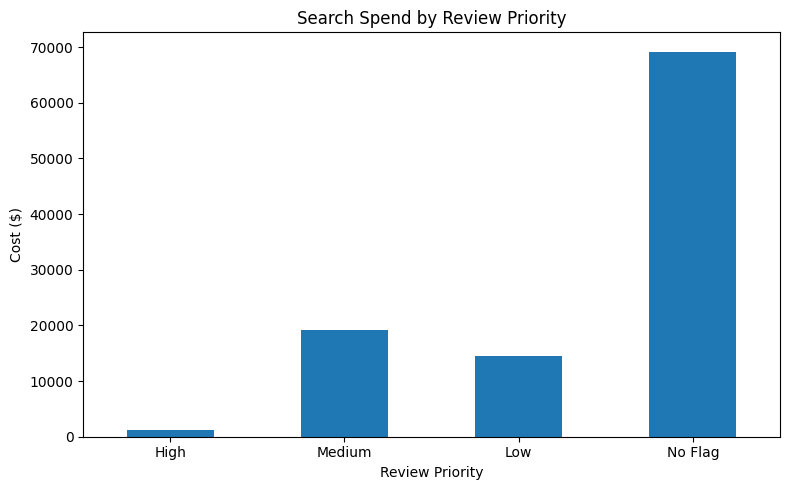

In [ ]:
# visualize and export ad spend by review priority

priority_order = ["High", "Medium", "Low", "No Flag"]

priority_spend = (
    df.groupby("Review Priority")["Cost"]
    .sum()
    .reindex(priority_order, fill_value=0)
)

plt.figure(figsize=(8, 5)) # sets fig dimensions
priority_spend.plot(kind="bar")

plt.title("Search Spend by Review Priority")
plt.xlabel("Review Priority")
plt.ylabel("Cost ($)")
plt.xticks(rotation=0) # keeps labels horizontal
plt.tight_layout()

Path("images").mkdir(exist_ok=True)
plt.savefig("images/spend_by_priority.png", dpi=150)
plt.show()

# chart helps us understand how much ad spend is associated with different review priorities


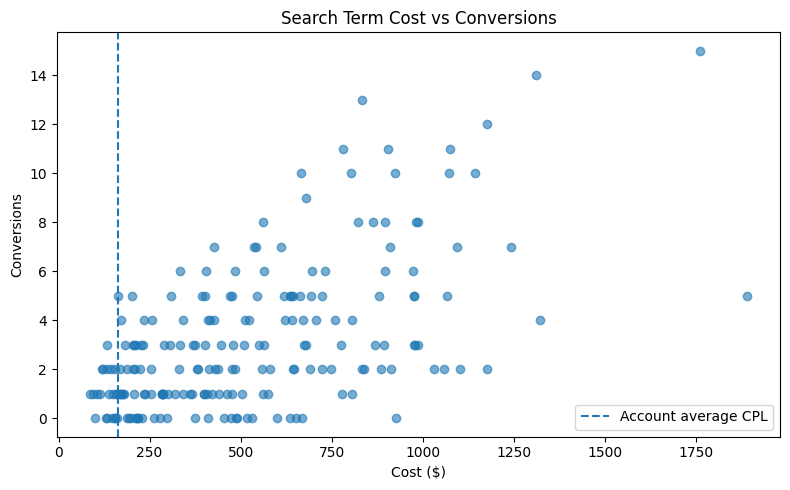

In [ ]:
# visualize search term spend vs conv. to identify potential inefficiencies

plt.figure(figsize=(8, 5))

plt.scatter(
    df["Cost"],
    df["Conversions"],
    alpha=0.6 # makes the points partially transparent, helps with overlap
)

plt.axvline(
    account_cpl,
    linestyle="--",
    label="Account average CPL"
)

plt.title("Search Term Cost vs Conversions")
plt.xlabel("Cost ($)")
plt.ylabel("Conversions")
plt.legend()
plt.tight_layout()

plt.savefig("images/cost_vs_conversions.png", dpi=150)
plt.show()

# each point represents a search term record
# spend vs conv.
# the lower-right region is particularly interesting coz it contains queries with relatively high spend + 0/no conv.
# however, the vertical line alone doesn't identify inefficiency for converting queries.

In [ ]:

# 1. confirm every exported query has a positive score
assert (final_report["Waste Risk Score"] > 0).all()

# 2. confirm scores are valid
assert df["Waste Risk Score"].between(0, 100).all()

# 3. confirm no-conversion flags are applied correctly
assert (
    df.loc[df["Flag High Spend No Conversion"], "Conversions"] == 0
).all()

# 4. confirm high-CPL flags have conversions
assert (
    df.loc[df["Flag High CPL"], "Conversions"] > 0
).all()

# 5. confirm the export contains the expected columns
assert list(final_report.columns) == report_columns

# 6. confirm the exported file exists
assert Path("output/flagged_search_terms.csv").exists()

print("All validation checks passed.")


All validation checks passed.
